# 03 · Optimización de primer orden

**Objetivo:** ver experimentalmente cómo la tasa de aprendizaje, el condicionamiento,
el momentum y el tamaño de minilote afectan la convergencia.

Teoría de referencia para $f$ cuadrática con Hessiana $H$ (autovalores $\mu \le \dots \le L$):
- GD es estable si y solo si $\eta < 2/L$.
- Con $\eta = 1/L$ el error se contrae por un factor $(1 - 1/\kappa)$ por iteración.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from common import set_seed, setup_style

setup_style()
rng = set_seed(42)
from applied_math import gradient_descent, minibatch_sgd, mse, mse_gradient

## 1. Efecto de la tasa de aprendizaje

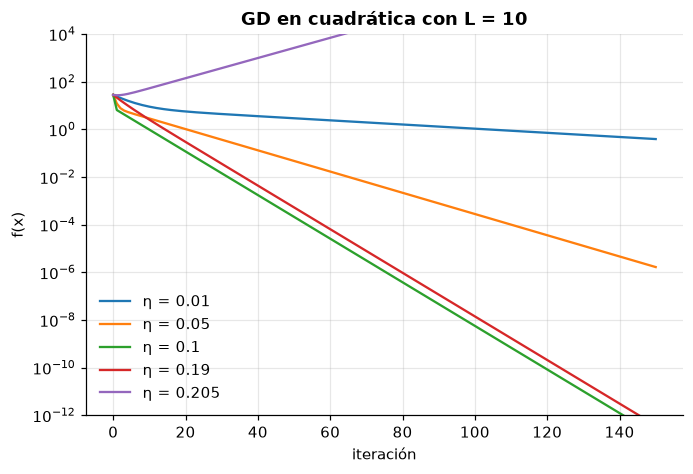

In [2]:
H = np.diag([1.0, 10.0])  # L = 10 → umbral de estabilidad η < 0.2


def f(x):
    return 0.5 * x @ H @ x


def grad_f(x):
    return H @ x


x0 = np.array([4.0, 2.0])
fig, ax = plt.subplots()
for lr in [0.01, 0.05, 0.1, 0.19, 0.205]:
    res = gradient_descent(f, grad_f, x0, lr=lr, max_iter=150)
    ax.semilogy(res.history, label=f"η = {lr}")
ax.set_xlabel("iteración")
ax.set_ylabel("f(x)")
ax.set_ylim(1e-12, 1e4)
ax.set_title("GD en cuadrática con L = 10")
ax.legend();

Con $\eta = 0.19$ (cerca del umbral) la coordenada de alta curvatura **oscila** sin divergir.
Con $\eta = 0.205 > 2/L$ diverge. Veámoslo en el plano:

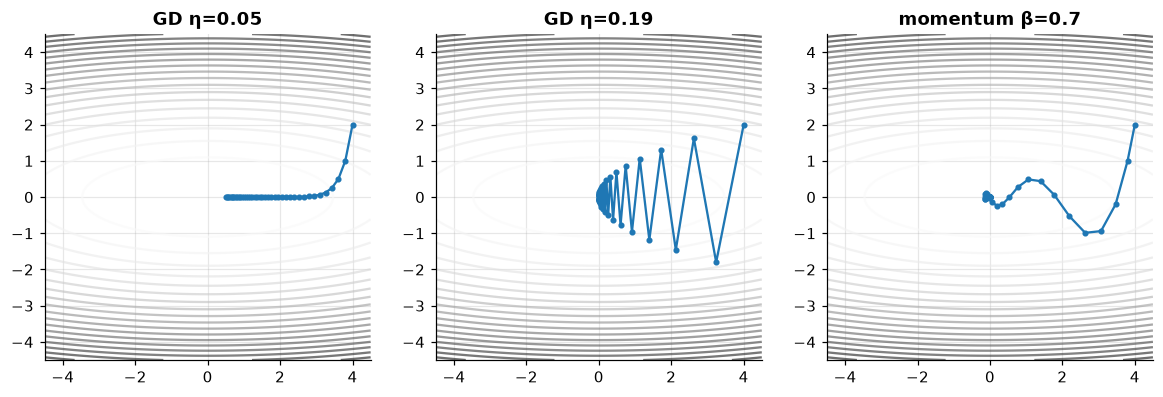

In [3]:
def path(lr, momentum=0.0, n=40):
    xs, x, v = [x0.copy()], x0.copy(), np.zeros(2)
    for _ in range(n):
        v = momentum * v - lr * grad_f(x)
        x = x + v
        xs.append(x.copy())
    return np.array(xs)


g = np.linspace(-4.5, 4.5, 200)
W1, W2 = np.meshgrid(g, g)
Z = 0.5 * (H[0, 0] * W1**2 + H[1, 1] * W2**2)
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (lr, mom, title) in zip(
    axes,
    [(0.05, 0, "GD η=0.05"), (0.19, 0, "GD η=0.19"), (0.05, 0.7, "momentum β=0.7")],
    strict=True,
):
    ax.contour(W1, W2, Z, levels=20, cmap="Greys", alpha=0.6)
    p = path(lr, mom)
    ax.plot(*p.T, "o-", ms=3)
    ax.set_title(title)
    ax.set_aspect("equal")

## 2. Condicionamiento: número de iteraciones vs. κ

Predicción teórica con $\eta = 1/L$: iteraciones $\propto \kappa$.

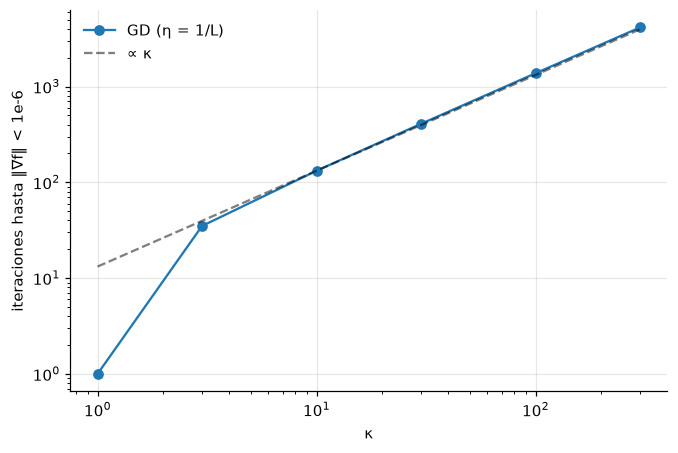

In [4]:
kappas = [1, 3, 10, 30, 100, 300]
iters = []
for k in kappas:
    Hk = np.diag([1.0, float(k)])
    r = gradient_descent(
        lambda x, Hk=Hk: 0.5 * x @ Hk @ x,
        lambda x, Hk=Hk: Hk @ x,
        np.ones(2),
        lr=1 / k,
        tol=1e-6,
        max_iter=100_000,
    )
    iters.append(r.n_iter)

fig, ax = plt.subplots()
ax.loglog(kappas, iters, "o-", label="GD (η = 1/L)")
ax.loglog(kappas, np.array(kappas) * iters[2] / kappas[2], "k--", alpha=0.5, label="∝ κ")
ax.set_xlabel("κ")
ax.set_ylabel("iteraciones hasta ‖∇f‖ < 1e-6")
ax.legend();

## 3. Por qué estandarizar features

Regresión con dos features en escalas muy distintas. Estandarizar cambia $X^\top X$
y por tanto $\kappa$ — el modelo es el mismo, el problema de optimización no.

In [5]:
n = 500
X_raw = np.column_stack([rng.normal(0, 1, n), rng.normal(0, 50, n)])
y = X_raw @ np.array([2.0, 0.05]) + rng.normal(scale=0.1, size=n)
X_std = (X_raw - X_raw.mean(0)) / X_raw.std(0)

for name, X_ in [("crudo", X_raw), ("estandarizado", X_std)]:
    Xb = np.column_stack([np.ones(n), X_])
    lams = np.linalg.eigvalsh(2 * Xb.T @ Xb / n)
    r = gradient_descent(
        lambda w, Xb=Xb: mse(w, Xb, y),
        lambda w, Xb=Xb: mse_gradient(w, Xb, y),
        np.zeros(3),
        lr=1 / lams[-1],
        tol=1e-6,
        max_iter=200_000,
    )
    print(f"{name:>14}: κ = {lams[-1] / lams[0]:>10.1f}  iteraciones = {r.n_iter}")

         crudo: κ =     2825.7  iteraciones = 42677
 estandarizado: κ =        1.0  iteraciones = 4


## 4. SGD por minilotes

Trade-off: lotes pequeños dan pasos baratos y ruidosos; lotes grandes, pasos caros y precisos.
Con $\eta$ constante, SGD no converge exactamente: queda oscilando en una bola alrededor del
óptimo cuyo radio crece con $\eta$ y con la varianza del gradiente.

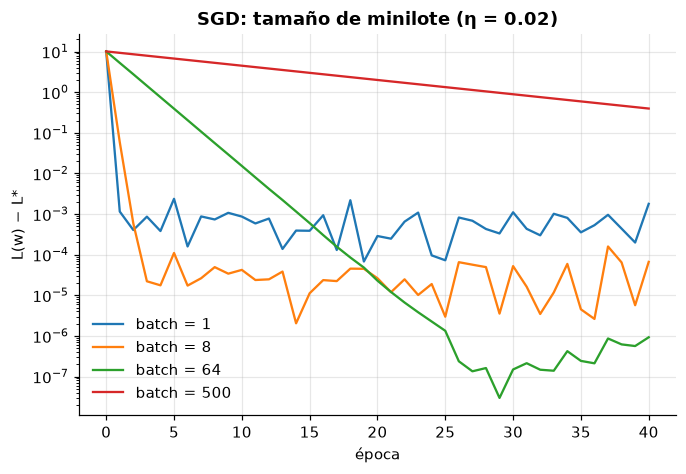

In [6]:
Xb = np.column_stack([np.ones(n), X_std])
w_star, *_ = np.linalg.lstsq(Xb, y, rcond=None)
L_star = mse(w_star, Xb, y)

fig, ax = plt.subplots()
for bs in [1, 8, 64, n]:
    r = minibatch_sgd(
        mse,
        mse_gradient,
        np.zeros(3),
        Xb,
        y,
        lr=0.02,
        batch_size=bs,
        epochs=40,
        rng=np.random.default_rng(0),
    )
    ax.semilogy(np.array(r.history) - L_star + 1e-12, label=f"batch = {bs}")
ax.set_xlabel("época")
ax.set_ylabel("L(w) − L*")
ax.set_title("SGD: tamaño de minilote (η = 0.02)")
ax.legend();

## Para llevar

- $\eta < 2/L$ es un límite duro; en la práctica se busca en escala logarítmica.
- El costo de GD crece con $\kappa$; estandarizar (o precondicionar) es la solución barata.
- Momentum acelera en valles alargados; la teoría da $O(\sqrt\kappa)$ con $\beta$ bien elegido.
- SGD por época cuesta lo mismo que GD, pero da $n/b$ pasos: en datasets grandes gana.